### Data Analysis




#### Regression $y=A+Bx$

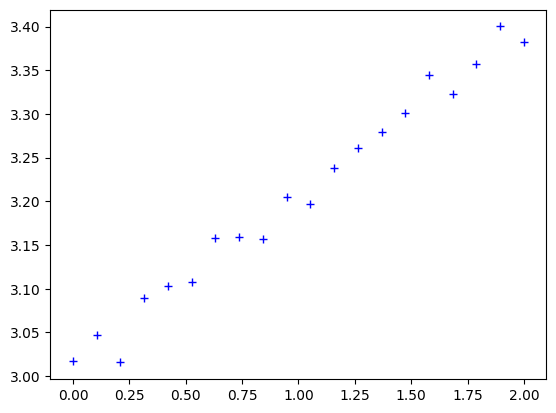

In [1]:
import numpy as np
t = np.linspace(0,2,20)
a = 0.20
v0 = 3.0
v = v0 + a * t + np.random.normal(loc=0.0,scale=0.02,size=np.size(t))
import matplotlib.pyplot as plt
plt.figure()
plt.plot(t,v,'b+')
plt.show()

![Alt text](image-2.png)

In [2]:
from numpy import sum
N = np.size(t)
A = (sum(t**2)*sum(v)-sum(t)*sum(t*v))/(N*sum(t**2)-sum(t)**2)
B = (N*sum(t*v)-sum(t)*sum(v))/(N*sum(t**2)-sum(t)**2)
print(A)
print(B)

3.0136122710745665
0.193491143394441


[3.01361227 0.19349114]
[0.00724389 0.00619245]
A = 3.014+/-0.007
B = 0.193+/-0.006


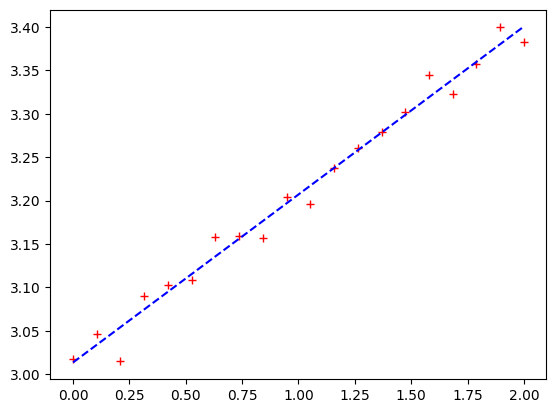

In [3]:
from scipy.optimize import curve_fit
def f(t,A,B):
    return A+B*t
param,cov = curve_fit(f,t,v)
print(param)
print(np.sqrt(np.diag(cov)))
import uncertainties as unc
A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
print('A = {}'.format(A))
print('B = {}'.format(B))
t_values = np.linspace(t[0],t[-1],100)
plt.figure()
plt.plot(t,v,'r+')
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()

dv = 0.016809291202328703


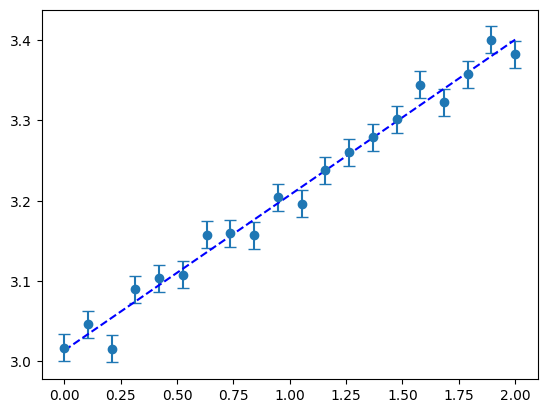

In [4]:
dv = np.std(v-f(t,*param),ddof=2)
print('dv = {}'.format(dv))
plt.figure()
plt.errorbar(t,v,yerr=t*0+dv,fmt='o',capsize=4)
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()

Sensitivities with respect to data points

![Alt text](image.png)

![Alt text](image-1.png)

[ 0.18571429  0.17142857  0.15714286  0.14285714  0.12857143  0.11428571
  0.1         0.08571429  0.07142857  0.05714286  0.04285714  0.02857143
  0.01428571  0.         -0.01428571 -0.02857143 -0.04285714 -0.05714286
 -0.07142857 -0.08571429]
[-0.13571429 -0.12142857 -0.10714286 -0.09285714 -0.07857143 -0.06428571
 -0.05       -0.03571429 -0.02142857 -0.00714286  0.00714286  0.02142857
  0.03571429  0.05        0.06428571  0.07857143  0.09285714  0.10714286
  0.12142857  0.13571429]


<Figure size 640x480 with 0 Axes>

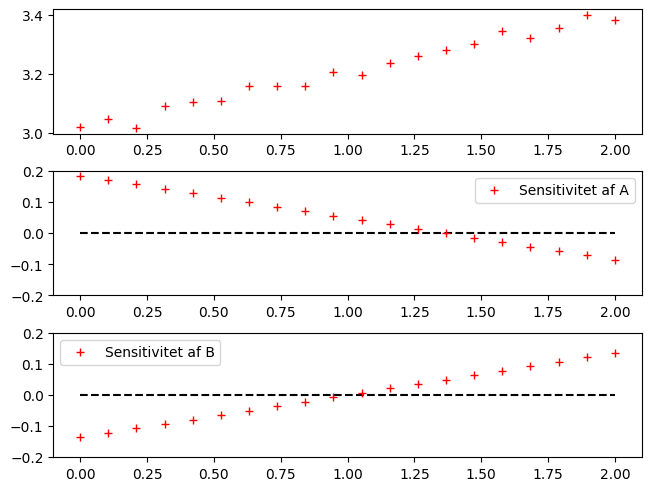

In [5]:
from numpy import sum
N = np.size(t)
A_sensitivity = (sum(t**2)-t*sum(t))/(N*sum(t**2)-sum(t)**2)
B_sensitivity = (N*t-sum(t))/(N*sum(t**2)-sum(t)**2)
print(A_sensitivity)
print(B_sensitivity)
import matplotlib.pyplot as plt
plt.figure()
plt.subplots(3,1,layout='constrained')
plt.subplot(311)
plt.plot(t,v,'r+')
plt.subplot(312)
plt.ylim(-0.2,0.2)
plt.plot([t[0],t[-1]],[0,0],'k--')
plt.plot(t,A_sensitivity,'r+',label='Sensitivitet af A')
plt.legend()
plt.subplot(313)
plt.ylim(-0.2,0.2)
plt.plot([t[0],t[-1]],[0,0],'k--')
plt.plot(t,B_sensitivity,'r+',label='Sensitivitet af B')
plt.legend()
plt.show()

[-0.13571429 -0.12142857 -0.10714286 -0.09285714 -0.07857143 -0.06428571
 -0.05       -0.03571429 -0.02142857 -0.00714286  0.00714286  0.02142857
  0.03571429  0.05        0.06428571  0.07857143  0.09285714  0.10714286
  0.12142857  0.13571429]


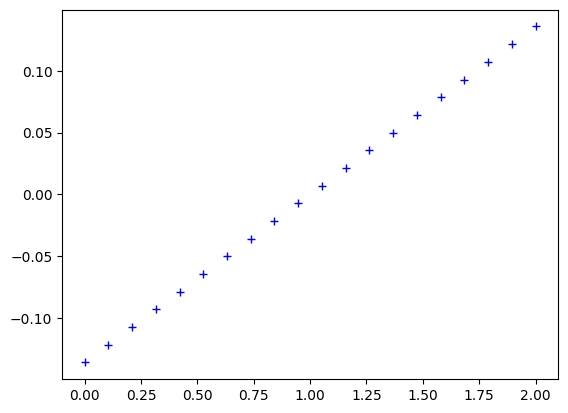

In [6]:
sensitivity = (np.size(t)*t-np.sum(t))/(np.size(t)*np.sum(t**2)-np.sum(t)**2)
print(sensitivity)
import matplotlib.pyplot as plt
plt.figure()
plt.plot(t,sensitivity,'b+')
plt.show()

##### Plotting with errorbars


$\delta v=\sqrt{\frac{\sum_i \left(v_i-(A+Bt_i)\right)^2}{N-2}}$
```python
dv = np.std(v-f(t,*param),ddof=2)
```
Note the ddof=2 which is due to the fact that we have determined two parameters, *A,B*.

dv = 0.016809291202328703


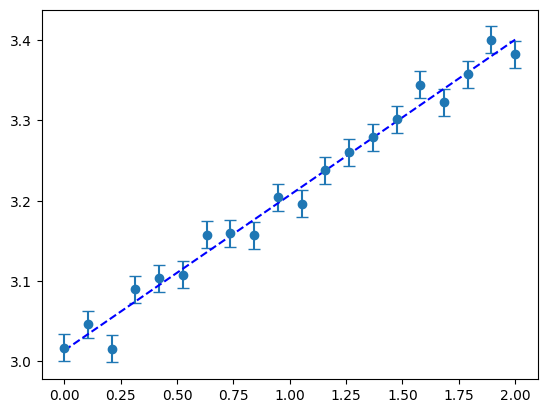

In [7]:
dv = np.std(v-f(t,*param),ddof=2)
print('dv = {}'.format(dv))
plt.figure()
plt.errorbar(t,v,yerr=dv,fmt='o',capsize=4)
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()

#### Regression $y=A+Bx$ with $y$-uncertainties

The command
```python
dv = np.random.normal(loc=0.02,scale=0.005,size = np.size(t))
```
creates an array of normally distributed random numbers the mean 0.02 and standard deviation 0.005.
The size of the array is the same as the length of the array *t*.


```python
plt.errorbar(t,v,yerr=dv,fmt='o',capsize=4)
```
Plot the *v* variable as a function of times, *t*, and adds error bars from the array *dv*.

[0.01950808 0.02351745 0.02993128 0.01574459 0.02361291 0.0278865
 0.01562064 0.02061648 0.01509357 0.03119264 0.01083804 0.01381733
 0.02023101 0.02768224 0.02532183 0.01424326 0.01521792 0.02229489
 0.01435732 0.02138468]


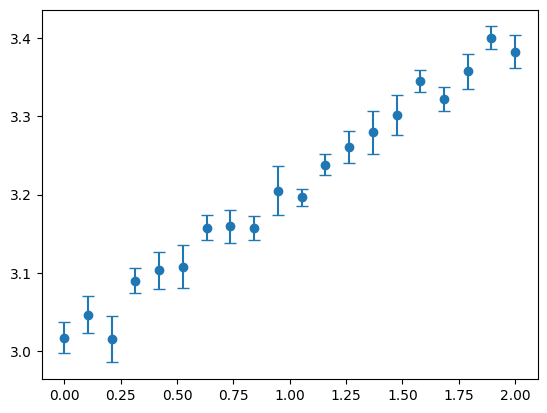

In [8]:
dv = np.random.normal(loc=0.02,scale=0.005,size = np.size(t))
print(dv)
plt.figure()
plt.errorbar(t,v,yerr=dv,fmt='o',capsize=4)
plt.show()

[3.01407802 0.19327142]
[0.00862008 0.00709248]
A = 3.014+/-0.009
B = 0.193+/-0.007


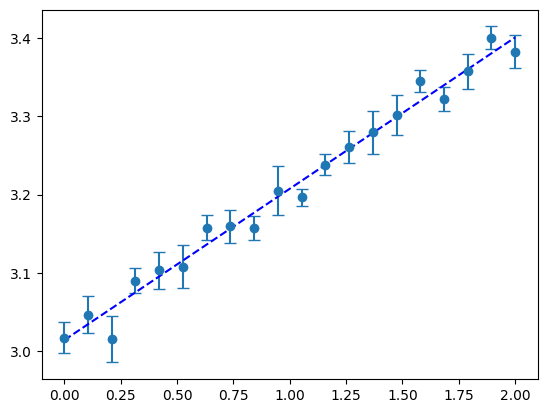

In [9]:
param,cov = curve_fit(f,t,v,sigma=dv,absolute_sigma=True)
print(param)
print(np.sqrt(np.diag(cov)))
import uncertainties as unc
A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
print('A = {}'.format(A))
print('B = {}'.format(B))
plt.figure()
plt.errorbar(t,v,yerr=dv,fmt='o',capsize=4)
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()

### Regression linear

#### Regression $y=A+Bx$ with $x$- and $y$-uncertainties

$y=A+Bx$

$\delta y =\left|B\right|\delta x$

$\delta y_\text{modified}=\sqrt{\delta y^2+B^2\delta x^2}$

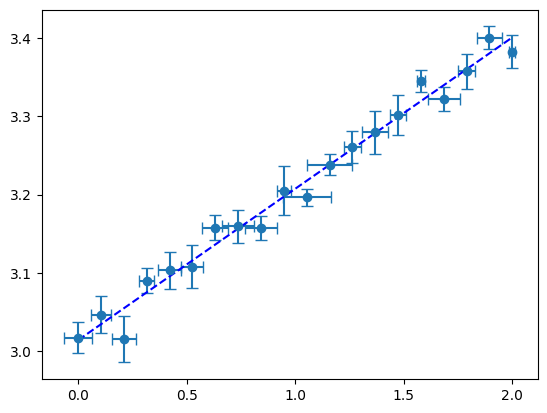

In [11]:
dt = np.random.normal(loc=0.05,scale=0.02,size = np.size(t))
plt.figure()
plt.errorbar(t,v,xerr=dt,yerr=dv,fmt='o',capsize=4)
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()

```python
dv = np.sqrt(dv_original**2+B.n**2*dt**2)
```

In [12]:
param,cov = curve_fit(f,t,v)
A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
print('A = {}, B = {} {:.8f} {:.8f}'.format(A,B,A.n,B.n))
dv_original = np.copy(dv)
for i in range(3):
    dv = np.sqrt(dv_original**2+B.n**2*dt**2)
    param,cov = curve_fit(f,t,v,sigma=dv,absolute_sigma=True)
    A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
    B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
    print('A = {}, B = {} {:.8f} {:.8f}'.format(A,B,A.n,B.n))

A = 3.014+/-0.007, B = 0.193+/-0.006 3.01361227 0.19349114
A = 3.017+/-0.010, B = 0.193+/-0.008 3.01731011 0.19330353
A = 3.017+/-0.010, B = 0.193+/-0.008 3.01730805 0.19330350
A = 3.017+/-0.010, B = 0.193+/-0.008 3.01730805 0.19330350


#### Regression - other functions

$y=A+Bx+Cx^2$

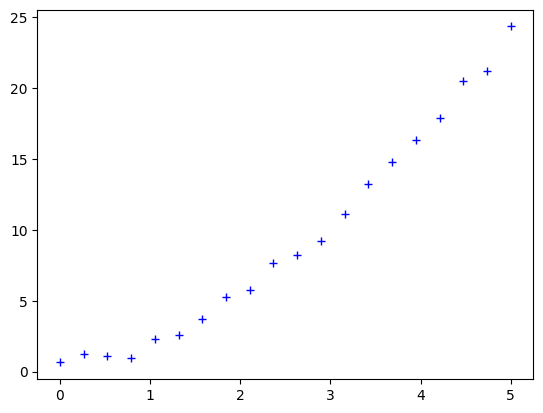

In [2]:
import numpy as np
t = np.linspace(0,5,20)
a = 1.50
v0 = 1.0
x0 = 0.5
x = x0 + v0 * t + 1/2 * a * t ** 2 + np.random.normal(loc=0.0,scale=0.5,size=np.size(t))
import matplotlib.pyplot as plt
plt.figure()
plt.plot(t,x,'b+')
plt.show()

[0.37453082 1.08610765 0.73921633]
[0.27330562 0.253362   0.04891536]
A = 0.37+/-0.27
B = 1.09+/-0.25
C = 0.74+/-0.05


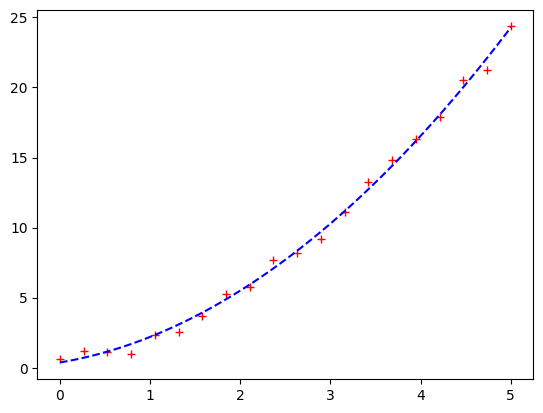

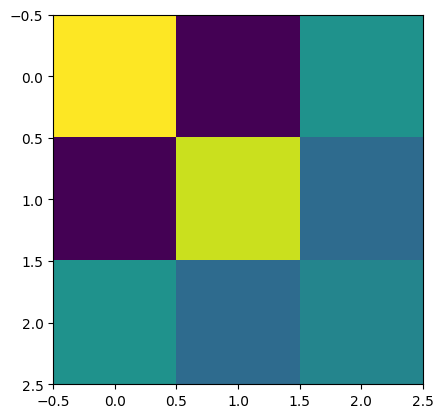

In [3]:
from scipy.optimize import curve_fit
def f(t,A,B,C):
    return A+B*t+C*t**2
param,cov = curve_fit(f,t,x)
print(param)
print(np.sqrt(np.diag(cov)))
import uncertainties as unc
A = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
B = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
C = unc.ufloat(param[2],np.sqrt(np.diag(cov))[2])
print('A = {}'.format(A))
print('B = {}'.format(B))
print('C = {}'.format(C))
t_values = np.linspace(t[0],t[-1],100)
plt.figure()
plt.plot(t,x,'r+')
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()
plt.imshow(cov)
plt.show()

#### Compute the uncertainty in the $y$-values

$\delta x=\sqrt{\frac{x_i-(A+Bt_i+Ct_i^2)}{N-3}}$
```python
dx = np.std(x-f(t,*param),ddof=3)
```
Note the ddof=3 which is due to the fact that we have determined three parameters, *A,B,C*.

dx = 0.5630234591970116


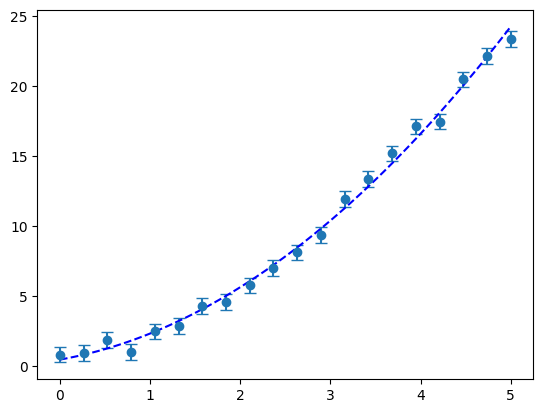

In [27]:
dx = np.std(x-f(t,*param),ddof=3)
print('dx = {}'.format(dx))
plt.figure()
plt.errorbar(t,x,yerr=t*0+dx,fmt='o',capsize=4)
plt.plot(t_values,f(t_values,*param),'b--')
plt.show()

#### Transformation of data

Taking logarithms on both sides of an exponential function
$y=A\text{e}^{Bx}$ leads to a linear function, $\ln y=\ln A +{Bx}$, in $(x,\ln y)$.

Taking logarithms on both sides of a power function
$y=Ax^{B}$ leads to a linear function, $\ln y=\ln +B \ln x$, in $(\ln x,\ln y)$.

A logarithmic function $y=A+B\ln(x)$ is already linear in $(\ln x,y)$.

A quadratic polynomial 
$y=A+Bx+Cx^2$
can be tranformed into a linear function if we plot 
$(x,\frac{y-y_0}{x-x_0})$
where $(x_0,y_0)$ is a data point.

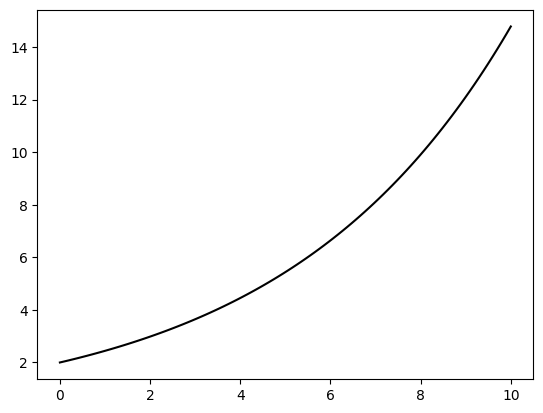

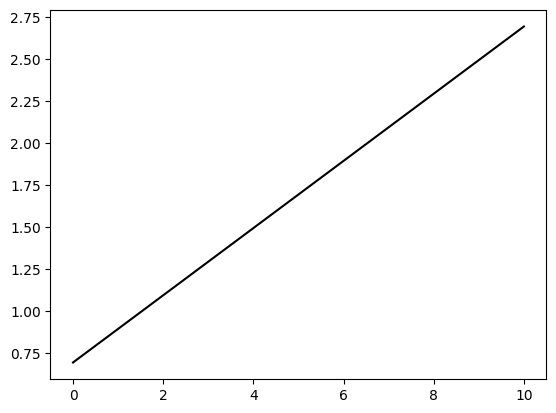

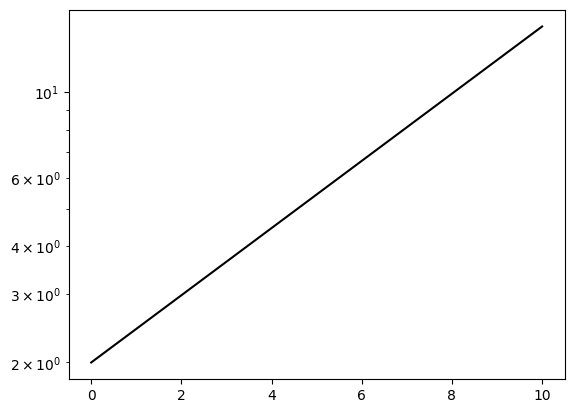

In [ ]:
import numpy as np
A = 2.0
B = 0.2
x = np.linspace(0,10,100)
y = A * np.exp( B * x )
plt.figure()
plt.plot(x,y,'k-')
plt.show()
plt.plot(x,np.log(y),'k-')
plt.show()
plt.semilogy(x,y,'k-')
plt.show()

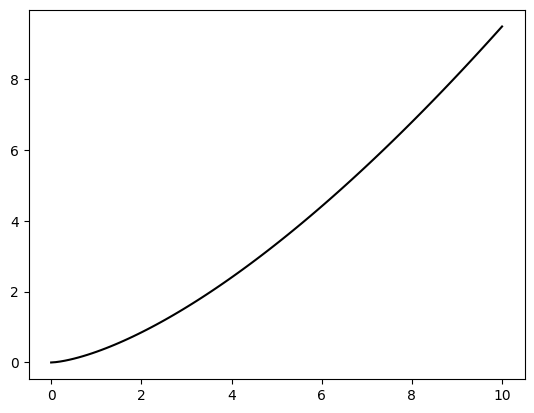

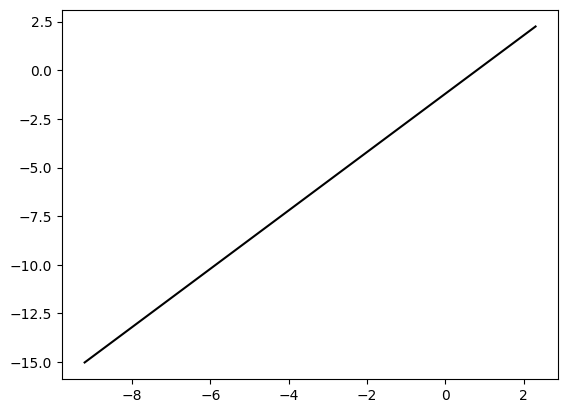

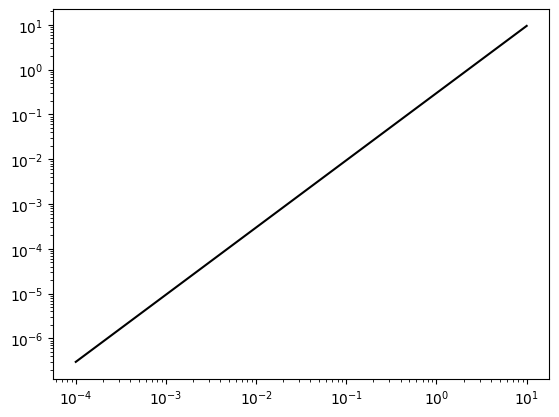

In [ ]:
import numpy as np
A = 0.3
B = 1.5
x = np.linspace(0.0001,10,100)
y = A * x ** B
plt.figure()
plt.plot(x,y,'k-')
plt.show()
plt.plot(np.log(x),np.log(y),'k-')
plt.show()
plt.loglog(x,y,'k-')
plt.show()

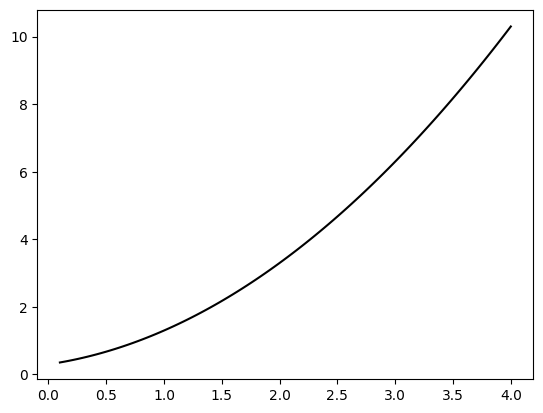

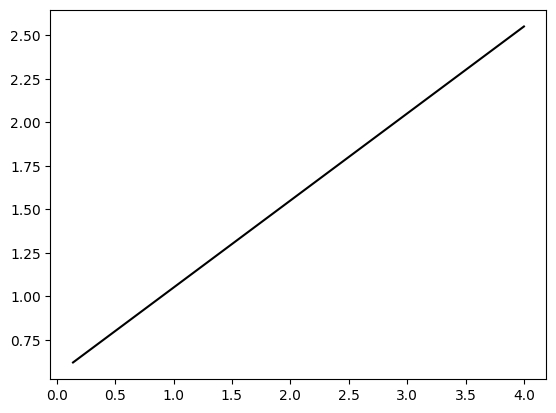

In [ ]:
import numpy as np
A = 0.3
B = 0.5
C = 0.5
x = np.linspace(0.1,4,100)
y = A + B * x + C * x ** 2
plt.figure()
plt.plot(x,y,'k-')
plt.show()
plt.plot(x[1:],(y[1:]-y[0])/(x[1:]-x[0]),'k-')
plt.show()

#### Importing data

In [ ]:
import numpy as np
import pandas as pd
velocity_df = pd.read_csv("data/20230802-125155_Wheel.csv")
display(velocity_df.head())

,index,frame,sample,time,raw[0],cal[0],raw[1],cal[1],raw[2],cal[2]
0,0,10,0,0.01,14,0.0270,14,1.33333,14,-0.666667
1,1,11,0,0.02,27,0.0335,13,1.32500,-1,-0.500000
2,2,12,0,0.03,40,0.0402,13,1.34000,0,-0.545455
3,3,13,0,0.04,53,0.0534,13,1.32000,0,-0.467532
4,4,14,0,0.05,67,0.0666,14,1.32000,1,-0.306493


In [ ]:
velocity_df = pd.read_csv("data/20230802-125155_Wheel.csv",usecols=[3,7])
display(velocity_df.head())

,time,cal[1]
0,0.01,1.33333
1,0.02,1.32500
2,0.03,1.34000
3,0.04,1.32000
4,0.05,1.32000


In [ ]:
t = velocity_df.iloc[:,0]
v = velocity_df.iloc[:,1]
print(t[0:5])
print(v[0:5])

0    0.01
1    0.02
2    0.03
3    0.04
4    0.05
Name:  time, dtype: float64
0    1.33333
1    1.32500
2    1.34000
3    1.32000
4    1.32000
Name:  cal[1], dtype: float64


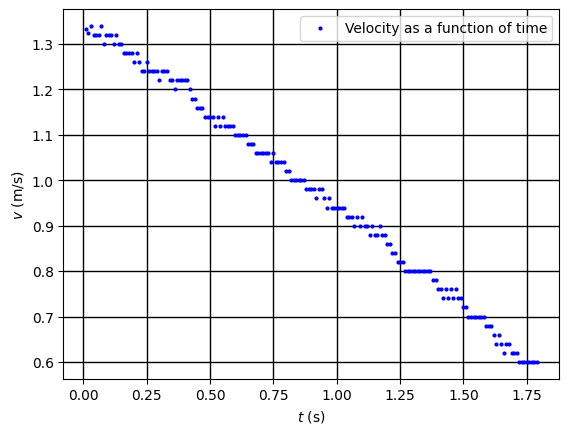

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(t,v,'bo',markersize=2,label='Velocity as a function of time')
plt.xlabel('$t$ (s)')
plt.ylabel('$v$ (m/s)')
plt.grid(color='k', linestyle='-', linewidth=1)
plt.legend()
plt.show()

In [ ]:
from scipy.optimize import curve_fit
def f(t,v0,a):
    return v0+a*t
param,cov = curve_fit(f,t,v)
import uncertainties as unc
V0 = unc.ufloat(param[0],np.sqrt(np.diag(cov))[0])
A = unc.ufloat(param[1],np.sqrt(np.diag(cov))[1])
print('v0 = {}'.format(V0))
print('a = {}'.format(A))

v0 = 1.3618+/-0.0020
a = -0.4263+/-0.0019


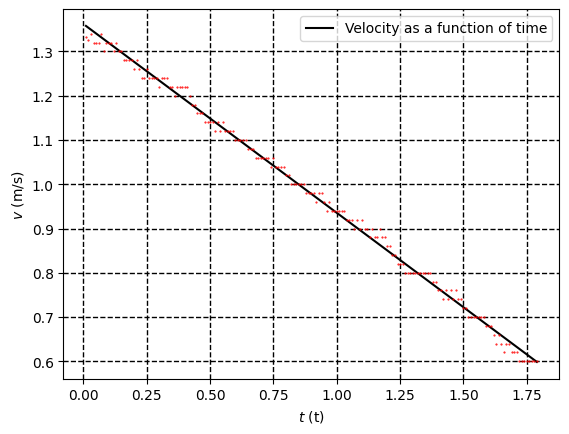

In [ ]:
z = f(t,*param)
plt.figure()
plt.plot(t,z,'-k',markersize=1,label='Velocity as a function of time')
plt.plot(t,v,'.r',markersize=1)
plt.xlabel('$t$ (t)')
plt.ylabel('$v$ (m/s)')
plt.grid(color='k', linestyle='--', linewidth=1)
plt.legend()
plt.show()

In [ ]:
dv = np.std(v-f(t,*param),ddof=2)
print('dv = {}'.format(dv)) 

dv = 0.013146473502295574


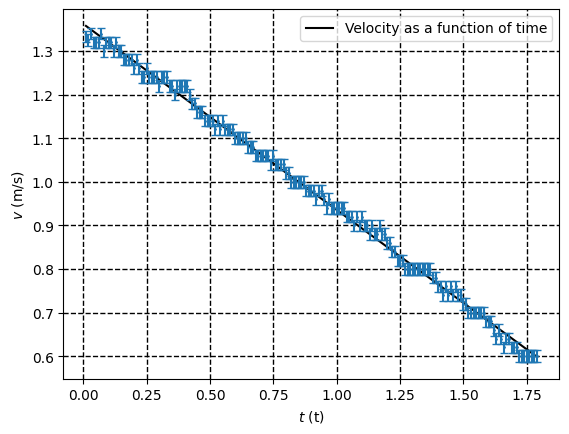

In [ ]:
plt.figure()
plt.plot(t,z,'-k',markersize=1,label='Velocity as a function of time')
plt.errorbar(x=t,y=v,yerr=dv,capsize=3,fmt='o',markersize=1)
plt.xlabel('$t$ (t)')
plt.ylabel('$v$ (m/s)')
plt.grid(color='k', linestyle='--', linewidth=1)
plt.legend()
plt.show()